# 🚀 Practice Day 42

**📅 Date:** **2026-10-20**  
**📁 Category:** **Phase 4 · 캡스톤2(구독 서비스 이탈 Churn) (Round 3/3)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Investigate subscriber churn for a B2B SaaS product — who's leaving, and which signals (tenure, engagement, support issues, plan tier) actually relate to it
  (B2B SaaS 구독자 이탈을 조사하기 — 누가 이탈하는지, tenure·참여도·CS 이슈·요금제 중 어떤 신호가 실제로 이탈과 관련 있는지)
- Compare churned vs retained subscribers and build your own view of what predicts churn here
  (이탈 고객과 유지 고객을 비교하고, 무엇이 이탈을 예측하는지 스스로 관점을 세워보기)

---
# 📂 Dataset

**Dataset Name:** Flowdesk Collaboration SaaS — Subscriber Data / Flowdesk 협업툴 SaaS — 구독자 데이터

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 240 SaaS subscribers (single table), including plan type (Basic/Pro/Enterprise), months subscribed (tenure_months), monthly active days (monthly_active_days), number of support tickets filed (support_tickets), and whether they churned (0/1). Clean — no missing values or duplicates.
(240명의 협업툴 SaaS 구독자 데이터(단일 테이블)로, 요금제(Basic/Pro/Enterprise), 구독 유지 개월수(tenure_months), 월간 활성 일수(monthly_active_days), 고객지원 문의 건수(support_tickets), 이탈 여부(churned: 0/1)를 포함합니다. 결측치·중복 없이 깨끗합니다.)

## Dataset Preview

In [20]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate SaaS subscriber data with realistic churn drivers ---
n = 240
plan_type = rng.choice(['Basic', 'Pro', 'Enterprise'], size=n, p=[0.45, 0.35, 0.20])
tenure_months = np.clip(rng.exponential(10, n), 1, 48).round().astype(int)
monthly_active_days = np.clip(rng.normal(16, 7, n), 0, 30).round().astype(int)
support_tickets = rng.poisson(1.0, n)
support_tickets = support_tickets + (monthly_active_days < 8).astype(int) * rng.integers(0, 2, n)

# churn probability: longer tenure and more active days lower it; support tickets and Basic plan raise it
plan_churn_bump = {'Basic': 0.65, 'Pro': 0.0, 'Enterprise': -1.8}
z = (
    -0.5
    - 0.11 * tenure_months
    - 0.15 * monthly_active_days
    + 0.45 * support_tickets
    + np.array([plan_churn_bump[p] for p in plan_type])
)
p_churn = 1 / (1 + np.exp(-z))
churned = rng.binomial(1, p_churn)

df = pd.DataFrame({
    'subscriber_id': [f'U{str(i+1).zfill(4)}' for i in range(n)],
    'plan_type': plan_type,
    'tenure_months': tenure_months,
    'monthly_active_days': monthly_active_days,
    'support_tickets': support_tickets,
    'churned': churned
})
df = df.sample(frac=1, random_state=99).reset_index(drop=True)

df.head(10)


,subscriber_id,plan_type,tenure_months,monthly_active_days,support_tickets,churned
0,U0230,Basic,1,11,0,0
1,U0050,Basic,10,18,1,0
2,U0163,Basic,3,9,0,0
3,U0129,Basic,9,7,1,0
4,U0125,Basic,2,7,1,0
5,U0055,Pro,11,9,1,0
6,U0052,Basic,27,11,1,0
7,U0146,Basic,8,18,1,0
8,U0195,Basic,22,4,2,0
9,U0157,Basic,23,18,2,0


## Dataset Information

In [21]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   subscriber_id        240 non-null    str  
 1   plan_type            240 non-null    str  
 2   tenure_months        240 non-null    int64
 3   monthly_active_days  240 non-null    int64
 4   support_tickets      240 non-null    int64
 5   churned              240 non-null    int64
dtypes: int64(4), str(2)
memory usage: 11.4 KB

Shape: (240, 6)


,subscriber_id,plan_type,tenure_months,monthly_active_days,support_tickets,churned
count,240,240,240.000000,240.000000,240.000000,240.000000
unique,240,3,NaN,NaN,NaN,NaN
top,U0230,Basic,NaN,NaN,NaN,NaN
freq,1,108,NaN,NaN,NaN,NaN
mean,NaN,NaN,10.391667,15.470833,0.966667,0.100000
std,NaN,NaN,10.067800,6.994258,1.018107,0.300627
min,NaN,NaN,1.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,3.000000,11.000000,0.000000,0.000000
50%,NaN,NaN,7.000000,15.000000,1.000000,0.000000
75%,NaN,NaN,14.000000,20.000000,1.250000,0.000000


---
# ❓ Business Questions

1. **(Analysis)** What is the overall churn rate, and how does it differ across the Basic, Pro, and Enterprise plans?
   (전체 이탈률은 몇 %이며, Basic/Pro/Enterprise 요금제 간 이탈률은 어떻게 다른가?)
2. **(Analysis)** How do churned and retained subscribers differ on average in tenure, monthly active days, and support tickets?
   (이탈 고객과 유지 고객은 평균 tenure·월간 활성일수·support tickets 측면에서 어떻게 다른가?)
3. **(Analysis)** Of tenure, monthly active days, and support tickets, which appears most strongly related to churn?
   (tenure·월간 활성일수·support tickets 중 이탈과 가장 관련이 깊어 보이는 요인은?)
4. **(Visualization)** Compare churn rate across the three plan types.
   (세 요금제 간 이탈률을 비교하면?)
5. **(Visualization)** Compare the distribution of monthly active days between churned and retained subscribers.
   (이탈 고객과 유지 고객의 월간 활성일수 분포를 비교하면?)

---
# 🔍 Data Cleaning Check


In [22]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
subscriber_id          0
plan_type              0
tenure_months          0
monthly_active_days    0
support_tickets        0
churned                0
dtype: int64

Duplicate rows: 0

Dtypes
subscriber_id            str
plan_type                str
tenure_months          int64
monthly_active_days    int64
support_tickets        int64
churned                int64
dtype: object

Column names
['subscriber_id', 'plan_type', 'tenure_months', 'monthly_active_days', 'support_tickets', 'churned']

Text columns — unique counts
subscriber_id    240
plan_type          3
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** What is the overall churn rate, and how does it differ across the Basic, Pro, and Enterprise plans? (전체 이탈률과 요금제별 이탈률은?)

**Result:** The overall churn rate is **10%**. Basic is **18.5%**, Pro is **3.4%**, and Enterprise is **2.3%**.  
(전체 이탈률은 10%. Basic 18.5%, Pro 3.4%, Enterprise 2.3%)

**Insight:** Basic is **16.2** percentage points above Enterprise and **15.1** above Pro. Pro is **1.0** point above Enterprise.  
(Basic이 Enterprise보다 16.2%p, Pro보다 15.1%p 높음. Pro는 Enterprise보다 1.0%p 높음)

In [23]:
# Question 1: overall churn rate + churn rate by plan_type
plan_rate = df.groupby('plan_type')['churned'].mean().sort_values(ascending=False)
print(plan_rate)
print(df['churned'].mean())

plan_type
Basic         0.185185
Pro           0.033708
Enterprise    0.023256
Name: churned, dtype: float64
0.1


## Question 2

**Question:** How do churned and retained subscribers differ on average in tenure, monthly active days, and support tickets? (이탈·유지 고객 간 평균 특성 차이는?)

**Result:** Retained subscribers average **11.01** months, **16.10** active days, and **0.89** tickets. Churned subscribers average **4.83** months, **9.79** active days, and **1.67** tickets.  
(유지 고객 평균은 11.01개월, 활성일 16.10일, 문의 0.89건. 이탈 고객 평균은 4.83개월, 활성일 9.79일, 문의 1.67건)

**Insight:** Churned subscribers have **6.18** fewer months and **6.31** fewer active days, and **0.78** more tickets.  
(이탈 고객은 유지 고객보다 기간이 6.18개월 짧고 활성일이 6.31일 적으며, 문의는 0.78건 많음)

In [24]:
# Question 2: churned vs retained subscribers - average tenure, active days, support tickets
# Direction: group by 'churned' and compare the averages for each feature
df.groupby('churned').agg({'tenure_months': 'mean', 'monthly_active_days': 'mean', 'support_tickets': 'mean'})

,tenure_months,monthly_active_days,support_tickets
churned,,,
0,11.009259,16.101852,0.888889
1,4.833333,9.791667,1.666667


## Question 3

**Question:** Of tenure, monthly active days, and support tickets, which appears most strongly related to churn? (이탈과 가장 관련 깊어 보이는 요인은?)

**Result:** The correlations with churn are monthly active days **-0.271**, support tickets **0.230**, and tenure **-0.184**.  
(이탈과의 상관계수는 월간 활성일수 -0.271, 문의 건수 0.230, 구독 개월 수 -0.184)

**Insight:** Monthly active days has the strongest link. Its absolute correlation is **0.041** above support tickets and **0.087** above tenure.  
(월간 활성일수의 관계가 가장 큼. 절대값이 문의보다 0.041, 구독 개월 수보다 0.087 큼)

In [25]:
# Question 3: which factor (tenure, active days, support tickets) relates most strongly to churn
# Direction: no single right method - correlations and the size of the churned-vs-retained gap are both fair game
print(df['churned'].corr(df['tenure_months']))
print(df['churned'].corr(df['monthly_active_days']))
print(df['churned'].corr(df['support_tickets']))

-0.1844146496242154
-0.27122415747688694
0.2296625502236753


---
# 📈 Visualization

**Chart 1:** Bar chart — churn rate by plan type (막대그래프: 요금제별 이탈률)

*Interpretation:* The bars follow the rate table: Basic **18.5%**, Pro **3.4%**, Enterprise **2.3%**.  
(막대 순서는 이탈률 표와 같음. Basic 18.5%, Pro 3.4%, Enterprise 2.3%)

---

**Chart 2:** Box plot — monthly active days by churn status (박스플롯: 이탈 여부별 월간 활성일수 분포)

*Interpretation:* The churned box (`churned` = 1) sits below the retained box (`churned` = 0). That matches the means, **9.79** days versus **16.10**.  
(이탈 박스(churned = 1)가 유지 박스(churned = 0)보다 아래에 있음. 평균 9.79일과 16.10일과 같음)

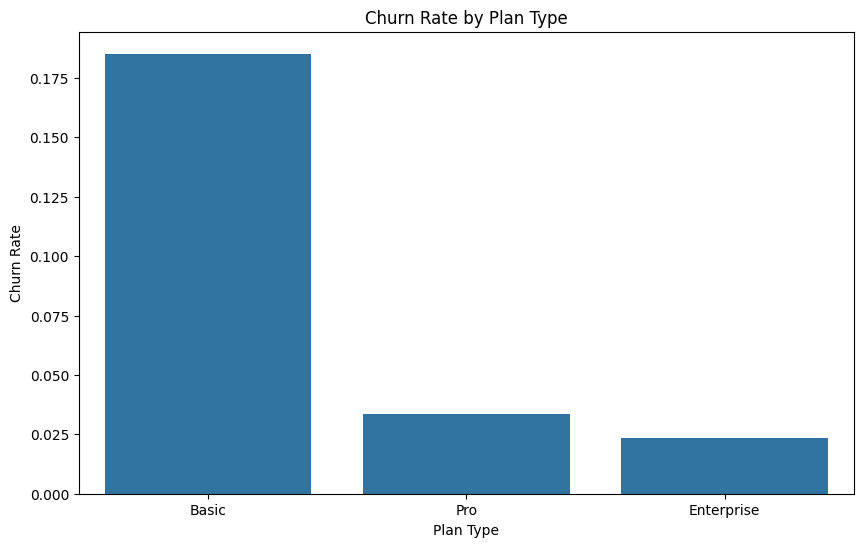

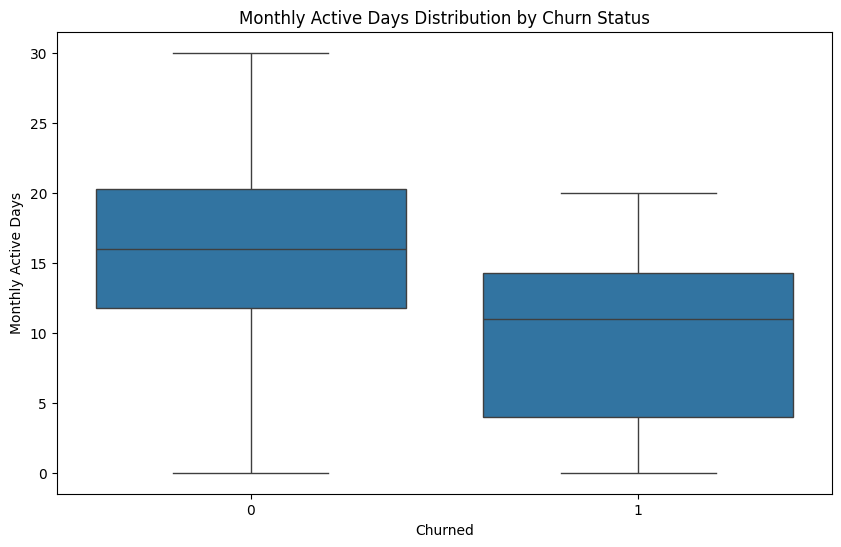

In [26]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: churn rate by plan type (bar)
fig, ax = plt.subplots(figsize=(10, 6))
plan_rate = df.groupby('plan_type')['churned'].mean().sort_values(ascending=False)
sns.barplot(x=plan_rate.index, y=plan_rate.values, ax=ax, errorbar=None)
ax.set_title('Churn Rate by Plan Type')
ax.set_xlabel('Plan Type')
ax.set_ylabel('Churn Rate')
plt.show()

# Chart 2: monthly active days distribution by churn status (box plot)
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x='churned', y='monthly_active_days', ax=ax, data=df)
ax.set_title('Monthly Active Days Distribution by Churn Status')
ax.set_xlabel('Churned')
ax.set_ylabel('Monthly Active Days')
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Overall churn is **10%**. Basic is **18.5%**, while Enterprise is **2.3%**.  
  (전체 이탈률은 10%. Basic은 18.5%, Enterprise는 2.3%)
- Churned subscribers average **4.83** months and **9.79** active days, against **11.01** months and **16.10** days for retained subscribers.  
  (이탈 고객 평균은 4.83개월, 활성일 9.79일. 유지 고객은 11.01개월, 16.10일)
- Monthly active days has the strongest correlation with churn, at **-0.271**.  
  (이탈과 상관계수가 가장 큰 항목은 월간 활성일수 -0.271)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Put retention effort on Basic first. Its churn rate is **18.5%**, **16.2** points above Enterprise.  
   (리텐션은 Basic부터. 이탈률 18.5%로 Enterprise보다 16.2%p 높음)
2. Watch subscribers with fewer active days. Churned subscribers average **9.79** days, **6.31** below retained subscribers, and the correlation is **-0.271**.  
   (활성일이 적은 구독자를 볼 것. 이탈 고객 평균은 9.79일로 유지 고객보다 6.31일 적고, 상관계수는 -0.271)
3. Treat support tickets as a second signal. Churned subscribers average **1.67** tickets versus **0.89**, and the correlation is **0.230**.  
   (문의 건수는 두 번째 신호로 볼 것. 이탈 고객 평균 1.67건, 유지 고객 0.89건, 상관계수 0.230)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- Q1 listed the plans in name order, so Enterprise sat above Pro even though its rate is lower.  
  (Q1이 이름순이라, 이탈률이 더 낮은 Enterprise가 Pro보다 위에 있었음)
- Chart 1 used `sns.barplot` on the raw rows, so each plan got a black 95% interval line.  
  (차트 1에서 원본 행을 `sns.barplot`에 넣어서 요금제마다 검은 95% 구간 선이 붙었음)
- Q3 printed the three correlations twice.  
  (Q3에서 상관계수 세 줄을 두 번 출력했음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- The mean of a 0/1 `churned` column is the churn rate. `sort_values(ascending=False)` puts Basic first.  
  (0/1 `churned`의 평균이 이탈률. `sort_values(ascending=False)`면 Basic이 맨 위)
- Grouping by `churned` compares retained (`0`) and churned (`1`) on tenure, active days, and tickets.  
  (`churned`로 묶으면 유지(0)와 이탈(1)의 개월 수, 활성일, 문의 건수를 비교함)
- The strongest link is the correlation with the largest absolute value: monthly active days **-0.271**. A rate bar uses that sorted table and `errorbar=None`.  
  (관계가 가장 큰 것은 절대값이 가장 큰 상관계수, 월간 활성일수 -0.271. 이탈률 막대는 그 정렬된 표를 쓰고 `errorbar=None`)  

---
# 🧠 Reflection

**What was difficult?**  
Deciding which of the three signals is strongest, and reading the plan bars past the extra lines.  
(세 신호 중 무엇이 가장 큰지 정하는 것, 그리고 막대 위의 추가 선을 빼고 읽는 것)

**Why?**  
The correlations have different signs, and `sns.barplot` on the raw rows draws a 95% interval.  
(상관계수 부호가 서로 다르고, 원본 행에 `sns.barplot`을 쓰면 95% 구간이 그려짐)

**How did I solve it?**  
Compared the absolute correlations, sorted the plan rates, and plotted those rates with `errorbar=None`.  
(상관계수는 절댓값으로 비교하고, 요금제 이탈률을 정렬한 뒤 `errorbar=None`으로 그림)

**What would I do differently next time?**  
Sort a rate table before plotting it, and check that a bar has no interval line.  
(이탈률 표를 정렬한 뒤에 그리고, 막대에 구간 선이 없는지 확인하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
The **10%** overall rate, the Basic gap, and the **-0.271** active-days correlation are clear. A rate bar still needs a check that it is not drawing an interval.  
(전체 10%, Basic 격차, 활성일 상관계수 -0.271은 이해함. 이탈률 막대는 구간 선이 아닌지 확인이 필요함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The three groupby comparisons were direct. The chart interval was the hard part.  
(세 개의 groupby 비교는 바로 보였음. 어려운 부분은 차트 구간 선이었음)
